# 01: Exploratory data analysis and model insights

Goals of this notebook:

1. **Understand the data:** quality issues, class balance, and how each feature relates to churn.
2. **Understand the trained model:** how well it separates churners, how its scores are distributed, and which features drive its predictions.
3. **Basic fairness check:** does it perform similarly across gender and age groups?

It reuses `churn.training.data.clean` / `split_data`, so it analyses exactly the data the model was trained on.

**Rerun:** `uv sync --group eda`, then `uv run churn-train`, then open this notebook with the `.venv` kernel.

In [1]:
import warnings

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import pandas as pd
from mlflow.tracking import MlflowClient
from sklearn.inspection import permutation_importance
from sklearn.metrics import precision_recall_curve, roc_curve

from churn.config import (
    CATEGORICAL_FEATURES,
    CHAMPION_ALIAS,
    NUMERIC_FEATURES,
    RANDOM_STATE,
    RAW_DATA_PATH,
    REGISTERED_MODEL_NAME,
    TARGET,
    default_tracking_uri,
)
from churn.training.data import clean, load_raw, split_data
from churn.training.evaluate import compute_metrics

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)

# Colour roles: blue = stays, orange = churns (validated colour-blind-safe pair).
STAYS, CHURNS = "#2a78d6", "#eb6834"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": "#9d9c95",
        "axes.labelcolor": MUTED,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "font.size": 9,
        "legend.frameon": False,
    }
)

## 1. Raw data: shape, types, quality

In [2]:
raw = load_raw(RAW_DATA_PATH)
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
quality = pd.DataFrame(
    {
        "dtype": raw.dtypes.astype(str),
        "n_unique": raw.nunique(),
        "n_missing": raw.isna().sum(),
        "n_blank": raw.astype(str).apply(lambda s: s.str.strip().eq("")).sum(),
    }
)
quality

,dtype,n_unique,n_missing,n_blank
customerID,str,7043,0,0
gender,str,2,0,0
SeniorCitizen,int64,2,0,0
Partner,str,2,0,0
Dependents,str,2,0,0
tenure,int64,73,0,0
PhoneService,str,2,0,0
MultipleLines,str,3,0,0
InternetService,str,3,0,0
OnlineSecurity,str,3,0,0


`TotalCharges` is stored as text because some values are blank. Who are those customers?

In [4]:
blank = raw["TotalCharges"].astype(str).str.strip().eq("")
print("duplicate rows ignoring customerID:", raw.drop(columns="customerID").duplicated().sum())
raw.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

duplicate rows ignoring customerID: 22


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


## 2. Target balance

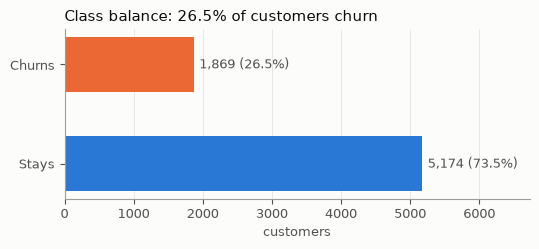

In [5]:
df = clean(raw)
counts = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 2.2))
bars = ax.barh(["Stays", "Churns"], counts.values, color=[STAYS, CHURNS], height=0.55)
for bar, n in zip(bars, counts.values, strict=True):
    ax.text(
        bar.get_width() + 80,
        bar.get_y() + bar.get_height() / 2,
        f"{n:,} ({n / len(df):.1%})",
        va="center",
        color=MUTED,
    )
ax.set_xlim(0, counts.max() * 1.3)
ax.grid(axis="y", visible=False)
ax.set_xlabel("customers")
ax.set_title(f"Class balance: {df[TARGET].mean():.1%} of customers churn", loc="left")
plt.show()

## 3. Numeric features vs churn

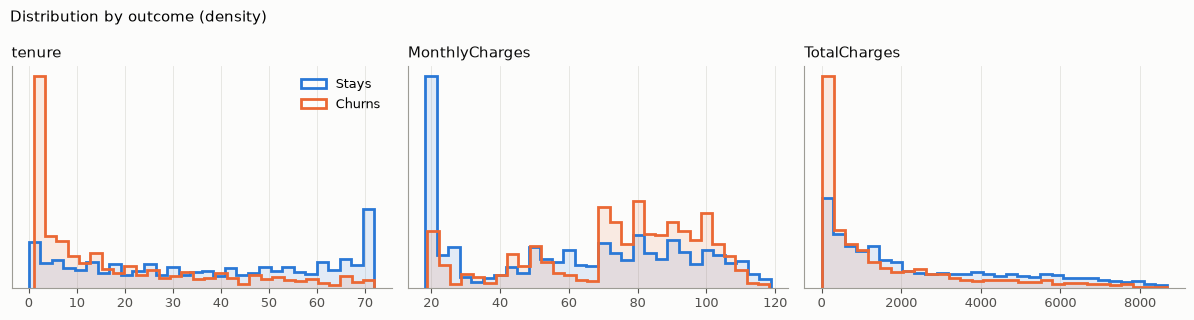

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col in zip(axes, NUMERIC_FEATURES, strict=True):
    for label, value, color in [("Stays", 0, STAYS), ("Churns", 1, CHURNS)]:
        data = df.loc[df[TARGET] == value, col].dropna()
        ax.hist(data, bins=30, density=True, histtype="step", lw=2, color=color, label=label)
        ax.hist(data, bins=30, density=True, alpha=0.12, color=color)
    ax.set_title(col, loc="left")
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
axes[0].legend()
fig.suptitle("Distribution by outcome (density)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

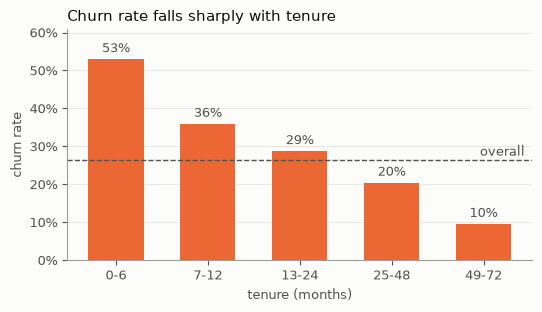

In [7]:
buckets = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6", "7-12", "13-24", "25-48", "49-72"],
)
rate = df.groupby(buckets, observed=True)[TARGET].mean()
fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(rate.index.astype(str), rate.values, color=CHURNS, width=0.6)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in rate.values], padding=3, color=MUTED)
ax.axhline(df[TARGET].mean(), color=MUTED, ls="--", lw=1)
ax.text(4.45, df[TARGET].mean() + 0.01, "overall", color=MUTED, ha="right")
ax.set_ylim(0, rate.max() * 1.15)
ax.set_xlabel("tenure (months)")
ax.set_ylabel("churn rate")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x", visible=False)
ax.set_title("Churn rate falls sharply with tenure", loc="left")
plt.show()

Correlation between numeric features. `TotalCharges` is roughly tenure × MonthlyCharges, so it is strongly correlated with tenure (multicollinearity: it matters for interpreting logistic-regression coefficients, not much for trees).

In [8]:
df[NUMERIC_FEATURES + [TARGET]].corr().round(2)

,tenure,MonthlyCharges,TotalCharges,Churn
tenure,1.00,0.25,0.83,-0.35
MonthlyCharges,0.25,1.00,0.65,0.19
TotalCharges,0.83,0.65,1.00,-0.20
Churn,-0.35,0.19,-0.20,1.00


## 4. Categorical features: churn rate per category

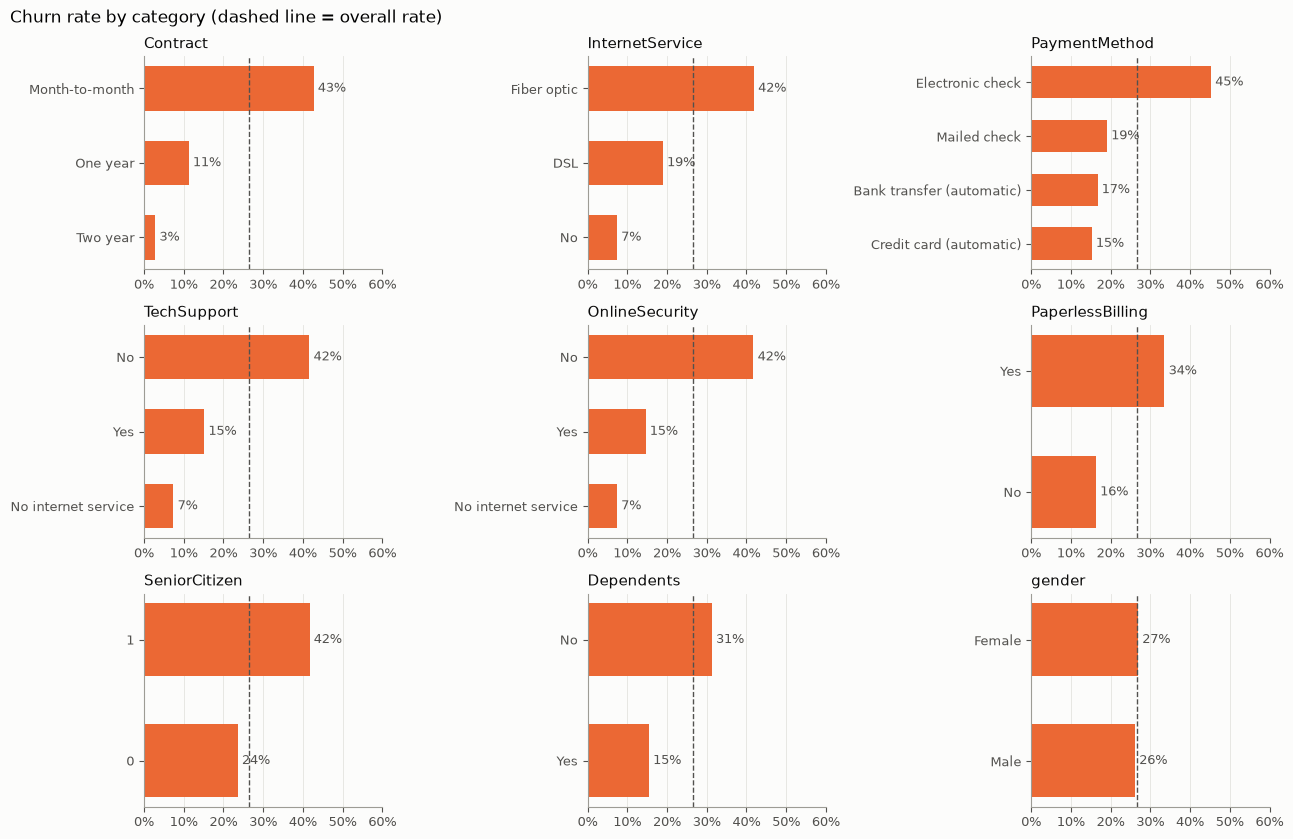

In [9]:
show = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "PaperlessBilling",
    "SeniorCitizen",
    "Dependents",
    "gender",
]
overall = df[TARGET].mean()
fig, axes = plt.subplots(3, 3, figsize=(13, 8.5))
for ax, col in zip(axes.flat, show, strict=True):
    r = df.groupby(col)[TARGET].mean().sort_values()
    bars = ax.barh(r.index.astype(str), r.values, color=CHURNS, height=0.6)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in r.values], padding=3, color=MUTED)
    ax.axvline(overall, color=MUTED, ls="--", lw=1)
    ax.set_xlim(0, 0.6)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.grid(axis="y", visible=False)
    ax.set_title(col, loc="left")
fig.suptitle(
    "Churn rate by category (dashed line = overall rate)", x=0.01, ha="left", fontsize=12
)
fig.tight_layout()
plt.show()

Rank all categorical features by **spread**: the gap between the highest- and lowest-churn category. A big spread means the feature separates churners well on its own.

In [10]:
spread = pd.DataFrame(
    {
        "lowest_rate": [df.groupby(c)[TARGET].mean().min() for c in CATEGORICAL_FEATURES],
        "highest_rate": [df.groupby(c)[TARGET].mean().max() for c in CATEGORICAL_FEATURES],
    },
    index=CATEGORICAL_FEATURES,
)
spread["spread"] = spread["highest_rate"] - spread["lowest_rate"]
spread.sort_values("spread", ascending=False).round(3)

,lowest_rate,highest_rate,spread
Contract,0.028,0.427,0.399
InternetService,0.074,0.419,0.345
OnlineSecurity,0.074,0.418,0.344
TechSupport,0.074,0.416,0.342
OnlineBackup,0.074,0.399,0.325
DeviceProtection,0.074,0.391,0.317
PaymentMethod,0.152,0.453,0.300
StreamingMovies,0.074,0.337,0.263
StreamingTV,0.074,0.335,0.261
SeniorCitizen,0.236,0.417,0.181


## 5. The champion model

Load `churn-model@champion` from the MLflow registry (the same model the API will serve) and recreate the identical test split.

In [11]:
mlflow.set_tracking_uri(default_tracking_uri())
mv = MlflowClient().get_model_version_by_alias(REGISTERED_MODEL_NAME, CHAMPION_ALIAS)
threshold = float(mv.tags["decision_threshold"])
model = mlflow.sklearn.load_model(f"models:/{REGISTERED_MODEL_NAME}@{CHAMPION_ALIAS}")

splits = split_data(df)
test_prob = pd.Series(model.predict_proba(splits.X_test)[:, 1], index=splits.X_test.index)
print(f"{REGISTERED_MODEL_NAME} v{mv.version} ({mv.tags['model_type']}), threshold={threshold:.3f}")
pd.Series(compute_metrics(splits.y_test, test_prob, threshold)).round(3)

churn-model v1 (xgboost_tuned), threshold=0.606


accuracy       0.787
precision      0.579
recall         0.725
f1             0.644
roc_auc        0.847
pr_auc         0.663
tn           838.000
fp           197.000
fn           103.000
tp           271.000
dtype: float64

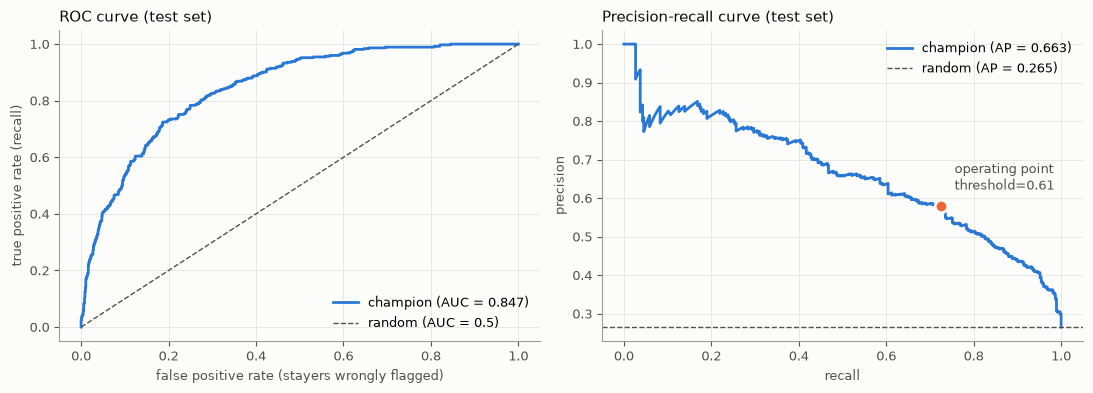

In [12]:
m = compute_metrics(splits.y_test, test_prob, threshold)
fpr, tpr, _ = roc_curve(splits.y_test, test_prob)
precision, recall, _ = precision_recall_curve(splits.y_test, test_prob)
base_rate = splits.y_test.mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(fpr, tpr, color=STAYS, lw=2, label=f"champion (AUC = {m['roc_auc']:.3f})")
ax1.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1, label="random (AUC = 0.5)")
ax1.set_xlabel("false positive rate (stayers wrongly flagged)")
ax1.set_ylabel("true positive rate (recall)")
ax1.legend(loc="lower right")
ax1.set_title("ROC curve (test set)", loc="left")

ax2.plot(recall, precision, color=STAYS, lw=2, label=f"champion (AP = {m['pr_auc']:.3f})")
ax2.axhline(
    base_rate, color=MUTED, ls="--", lw=1, label=f"random (AP = {base_rate:.3f})"
)
ax2.set_xlabel("recall")
ax2.set_ylabel("precision")
ax2.legend(loc="upper right")
ax2.plot(m["recall"], m["precision"], "o", ms=9, color=CHURNS, mec=SURFACE, mew=2)
ax2.annotate(
    f"operating point\nthreshold={threshold:.2f}",
    (m["recall"], m["precision"]),
    xytext=(10, 12),
    textcoords="offset points",
    color=MUTED,
)
ax2.set_title("Precision-recall curve (test set)", loc="left")
fig.tight_layout()
plt.show()

How the model's scores are distributed for customers who actually stayed vs churned. Good separation means the two humps barely overlap.

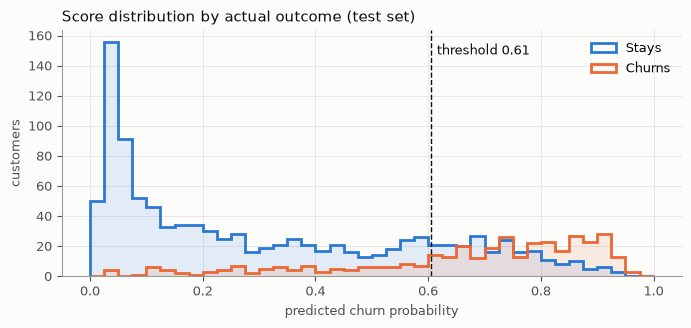

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for label, value, color in [("Stays", 0, STAYS), ("Churns", 1, CHURNS)]:
    s = test_prob[splits.y_test == value]
    ax.hist(s, bins=40, range=(0, 1), histtype="step", lw=2, color=color, label=label)
    ax.hist(s, bins=40, range=(0, 1), alpha=0.12, color=color)
ax.axvline(threshold, color=INK, ls="--", lw=1)
ax.text(threshold + 0.01, ax.get_ylim()[1] * 0.9, f"threshold {threshold:.2f}", color=INK)
ax.set_xlabel("predicted churn probability")
ax.set_ylabel("customers")
ax.legend()
ax.set_title("Score distribution by actual outcome (test set)", loc="left")
plt.show()

### Which features drive predictions? Permutation importance

For each input column: shuffle its values (breaking its link to the target), re-score, and measure how much **PR-AUC drops**. A big drop means the model relies on that column. This is model-agnostic and works on the *raw business columns* because the whole pipeline is scored. Computed on the validation set, 10 repeats; error bars = std across repeats.

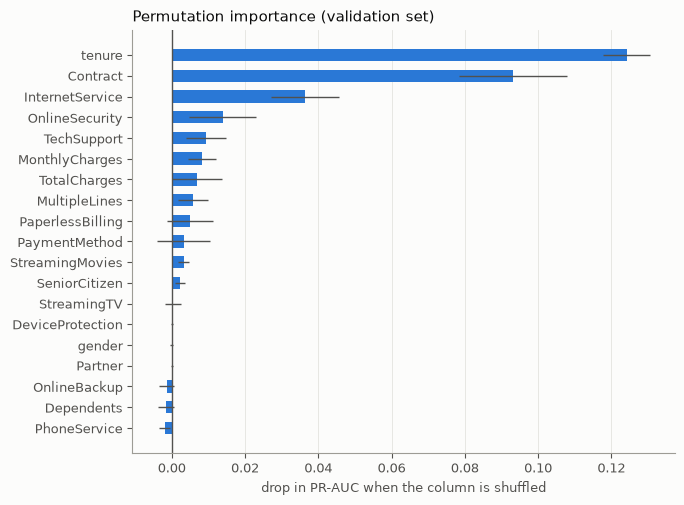

,drop_in_pr_auc,std
tenure,0.124,0.006
Contract,0.093,0.015
InternetService,0.036,0.009
OnlineSecurity,0.014,0.009
TechSupport,0.009,0.006
MonthlyCharges,0.008,0.004
TotalCharges,0.007,0.007
MultipleLines,0.006,0.004


In [14]:
result = permutation_importance(
    model,
    splits.X_val,
    splits.y_val,
    scoring="average_precision",
    n_repeats=10,
    random_state=RANDOM_STATE,
)
imp = pd.DataFrame(
    {"drop_in_pr_auc": result.importances_mean, "std": result.importances_std},
    index=splits.X_val.columns,
).sort_values("drop_in_pr_auc")

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(
    imp.index,
    imp["drop_in_pr_auc"],
    xerr=imp["std"],
    color=STAYS,
    height=0.6,
    error_kw={"ecolor": MUTED, "lw": 1},
)
ax.axvline(0, color=MUTED, lw=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("drop in PR-AUC when the column is shuffled")
ax.set_title("Permutation importance (validation set)", loc="left")
plt.show()
imp.sort_values("drop_in_pr_auc", ascending=False).round(4).head(8)

## 6. Fairness check

Compare performance across groups on the test set. We look for large gaps in **recall** (are churners in one group missed more often?) and **flagged rate** relative to the group's actual churn rate.

In [15]:
rows = []
for col in ["gender", "SeniorCitizen", "Partner", "Dependents"]:
    for group, idx in splits.X_test.groupby(col).groups.items():
        gm = compute_metrics(splits.y_test.loc[idx], test_prob.loc[idx], threshold)
        rows.append(
            {
                "feature": col,
                "group": group,
                "n": len(idx),
                "actual_churn_rate": splits.y_test.loc[idx].mean(),
                "flagged_rate": (gm["tp"] + gm["fp"]) / len(idx),
                "recall": gm["recall"],
                "precision": gm["precision"],
                "roc_auc": gm["roc_auc"],
            }
        )
fairness = pd.DataFrame(rows).set_index(["feature", "group"])
fairness.round(3)

n  actual_churn_rate  flagged_rate  recall  \
feature       group                                                   
gender        Female   687              0.281         0.344   0.715   
              Male     722              0.251         0.321   0.735   
SeniorCitizen 0       1187              0.233         0.286   0.692   
              1        222              0.441         0.577   0.816   
Partner       No       736              0.337         0.448   0.786   
              Yes      673              0.187         0.205   0.603   
Dependents    No       978              0.310         0.413   0.772   
              Yes      431              0.165         0.148   0.521   

                      precision  roc_auc  
feature       group                       
gender        Female      0.585    0.849  
              Male        0.573    0.846  
SeniorCitizen 0           0.562    0.848  
              1           0.625    0.786  
Partner       No          0.591    0.826  
              Yes         0.551    0.851  
Dependents    No          0.579    0.835  
              Yes         0.578    0.848

## 7. Findings

### Data quality
- **7,043 customers, 21 columns, no true missing values.** The only defect is 11 blank
  `TotalCharges`. All 11 have `tenure = 0` (signed up, not yet billed), so `clean()` sets
  them to 0. That's the true value, not an imputation.
- **22 rows are identical apart from `customerID`.** They're kept: with mostly yes/no
  columns, two real customers can easily share a profile. They aren't data-entry errors.
- **Imbalance: 26.5% churn.** That's why the project reports PR-AUC, recall and precision
  rather than accuracy.
- `TotalCharges` ≈ tenure × MonthlyCharges (correlation with tenure 0.83). This is
  redundant information. It's harmless for trees but makes logistic-regression
  coefficients harder to interpret.

### What drives churn (the business story)
1. **New customers leave.** Churn is 53% in the first 6 months, falling to 10% after 4
   years. This is the single strongest signal, and the model's top feature by
   permutation importance.
2. **Contract type.** Month-to-month 43% vs one-year 11% vs two-year 3%. There is nothing
   locking these customers in.
3. **Fibre optic customers churn at 42%, more than double DSL (19%),** despite paying
   for the premium product. Churners cluster at $70 to $105 monthly charges. This
   points to a price-versus-quality problem with the fibre offering.
4. **No tech support or online security:** about 42% churn vs 15% with them. These
   add-ons tie customers in (and may be a cheap retention lever).
5. **Electronic check payers churn at 45%** vs 15 to 19% for automatic payments.
   Manual payment is a monthly decision point to leave.
6. **Gender has no effect** (27% vs 26%). The model also gives it ~zero importance.

### The model (tuned XGBoost, `churn-model` v1)
- Test ROC-AUC **0.847**, PR-AUC **0.663** vs **0.265** for random guessing (2.5× lift).
- At threshold 0.61 it catches **72.5% of churners** (271 of 374), and 58% of flagged
  customers really do churn.
- Score distribution: stayers pile up near 0, churners spread over 0.6 to 0.95. The
  errors live in the overlap zone (~0.4 to 0.75).
- **Three features carry most of the signal:** tenure, Contract, InternetService. Around
  10 features contribute ~nothing. A much simpler model (or logistic regression) is a
  serious production candidate, and explaining predictions becomes easy.

### Fairness check (test set)
- **Gender: parity.** Recall 0.715 (F) vs 0.735 (M), ROC-AUC 0.849 vs 0.846.
- **Senior citizens: over-flagged and ranked less well.** 57.7% are flagged vs a 44.1%
  actual churn rate, and ROC-AUC drops to 0.786 (only 222 test seniors, so it's noisy).
  Age is a protected characteristic in many jurisdictions. If retention offers differ by
  who gets flagged, this needs monitoring.
- **Customers with dependents are under-served:** recall 0.52 vs 0.77 without.
  Half of churning family customers are missed, so their churn is driven by something
  the data doesn't capture well.
- These go into the model card as known limitations.

### Recommended business actions
Target month-to-month customers in their first 6 months; review fibre pricing and
quality; bundle tech support or security; nudge electronic-check payers to auto-pay
or longer contracts.
